## PtyChee iCoM Demo

Running 'find best rotate angle' and calculating iCoM

Author: Zeyu Wang <br>
October 2026

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from PtyChee import run

4D-STEM data and parameters read in.<br>
Data (from https://doi.org/10.1038/s41586-025-09693-6) are provided as .zip file in the 'data' folder and need to be unzipped into .npy files before running.

In [8]:
folder_path = 'data/'
file = 'MAPbI3_HT200_a13_ss0.3_31_F3sum.npy'
data_4D = np.load(folder_path+file)
print(data_4D.shape)

Voltage = 200               # keV, accelerate votage
alpha = 0.013               # rad, semi convergence angle
scan_step = 0.3             # Å,   scan step size

(800, 800, 38, 38)


This dataset was acquired with a total dose of only ~36 e<sup>-</sup>/Å<sup>2</sup>. By plotting a single CBED pattern, we can see just how sparse the signal is.

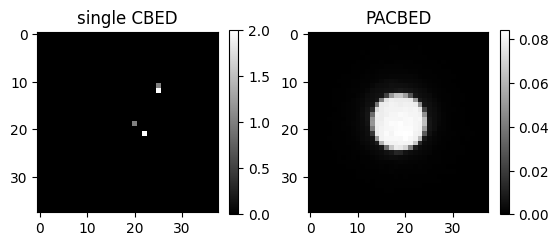

In [9]:
plt.subplot(121)
plt.imshow(data_4D[400,400], cmap='gray')
plt.title('single CBED')
plt.colorbar(shrink=0.5)
plt.subplot(122)
plt.imshow(np.mean(data_4D,axis=(0,1)), cmap='gray')
plt.title('PACBED')
plt.colorbar(shrink=0.5)
plt.show()

Run PtyChee.finRotate to calculate the optimized scan rotate angle


find best rotate angle and flip
File: MAPbI3_HT200_a13_ss0.3_31_F3sum.npy

#################### Data Information ####################
data shape: (800, 800, 38, 38)
data type: int8
CBED intensity range: 0 – 14
average CBED intensity: 9.6288480758667
BF center_Y: 18.581818181818182
BF center_X: 18.663636363636364
BF threshold: 0.5
Aperture Radius: 5.843108646253187 pixels

################## Original CoM Process ##################
inner_radiuss: 0 Alpha
outer_radius: 3 Alpha

################# Calculating Curl Curve #################
Best Scan Rotate Angle: 4.0 or -176.0 degrees
No Flipping Required

################### Saving and Ploting ###################
curl curve saving


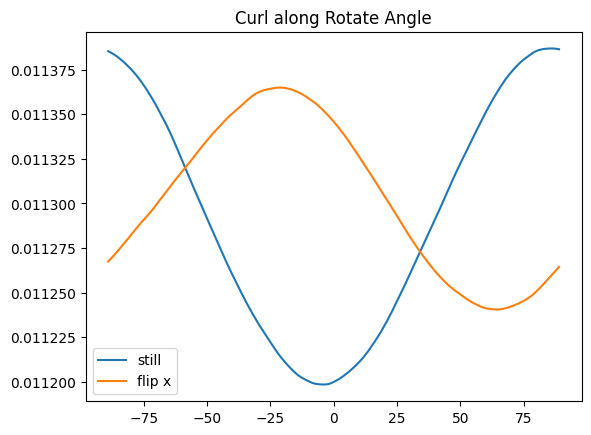

In [10]:
# Find Best Rotate and Flip From Curl
run.run_findRotateFromCurl(file, data_4D,
        inner_radius = 0,              # inner radius for the annular ROI on CBED, expressed as multiples of the aperture radius
        outer_radius = 3,              # outer radius for the annular ROI on CBED, expressed as multiples of the aperture radius
        save_results = False,          # set 'True' to save the results
)

According to the calculation results, we set scan_rotation_angle as '-176', note that set it to '4' in this case will cause an inversed contrast; <br>
And set scan_flip as 'False'


(It is worth noting that this method is not consistently robust for datasets with very large defocus values or very low doses. One way to assess the reliability of the results is to examine the two test curves shown above. When the two curves are approximately sinusoidal, the results are generally reliable. In contrast, if the curves deviate substantially from a sinusoidal shape, the results are generally unreliable.)

In [11]:
scan_rotation_angle = -176   # degrees
scan_flip = False            # flip X axis or not

Run CoM and iCoM


iCoM
File: MAPbI3_HT200_a13_ss0.3_31_F3sum.npy

################ Experimental Information ################
scan rotation angle: -176 degrees
scan flip x: False

#################### Data Information ####################
data shape: (800, 800, 38, 38)
data type: int8
CBED intensity range: 0 – 14
average CBED intensity: 9.6288480758667
BF center_Y: 18.581818181818182
BF center_X: 18.663636363636364
BF threshold: 0.5
Aperture Radius: 5.843108646253187 pixels

################## Original CoM Process ##################
inner_radiuss: 0 Alpha
outer_radius: 3 Alpha

##################### CoM Parameters #####################
CoM rotation angle: 176 degrees
CoM flip x: False

################# Jacobi iCoM Parameters #################
Number of Iterations: 1000

#################### dCoM Parameters #####################
calculating dCoM from: iCoM

################### Saving and Ploting ###################
CoM saving


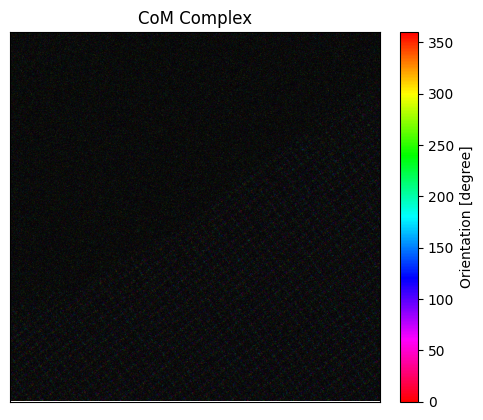

iCoM saving


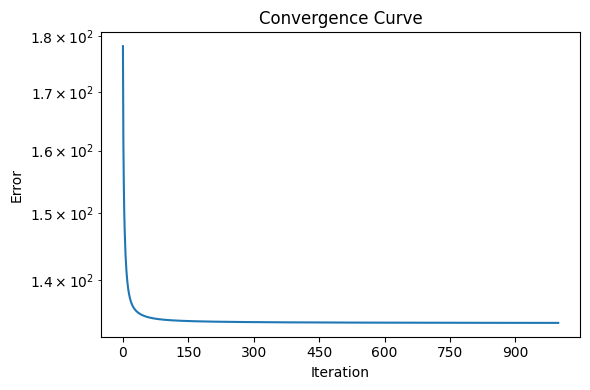

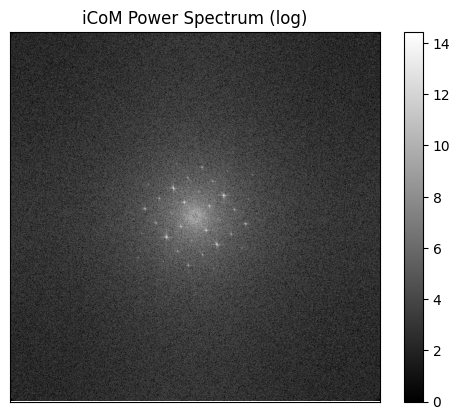

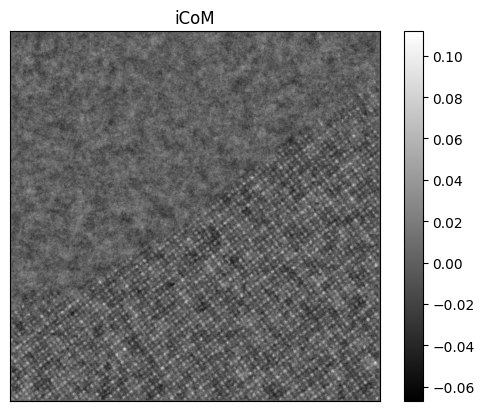

dCoM saving


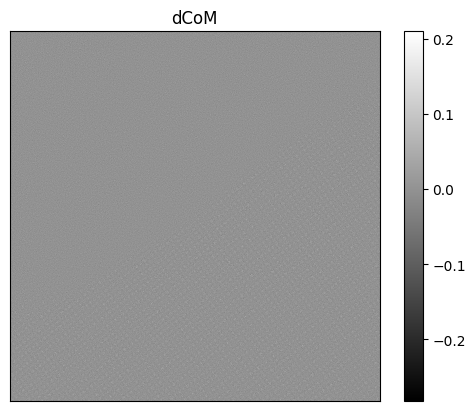

In [12]:
# CoM & iCoM
run.run_iCoM(file, data_4D, scan_rotation_angle, scan_flip, 
        inner_radius = 0,              # inner radius for the annular ROI on CBED, expressed as multiples of the aperture radius
        outer_radius = 3,              # outer radius for the annular ROI on CBED, expressed as multiples of the aperture radius

        mode = 'jacobi',               # 'anal' or 'iter' or 'jacobi'
        n_iter = 1000,                  # iteration nunber for jacobi iCoM

        save_results = False,          # set 'True' to save the results
);